1.데이터 가져오기

2.데이터 전처리

3.데이터 분리

4.PolynomialFeatures 다항추가

5.degree 추가

6.정규화작업

-데이터 학습

7.규제 적용후 데이터 학습

8.alpha값 변경후 데이터 학습 확인

9.데이터 예측

10.정확도

In [52]:
# 그래프 관련 import
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'Malgun Gothic'
# matplotlib.rcParams['font.family'] = 'AppleGothic'
matplotlib.rcParams['axes.unicode_minus']=False

# 판다스 관련 import
import pandas as pd
import numpy as np

# 인공지능 import
from sklearn import svm,metrics
from sklearn.neighbors import KNeighborsClassifier  #분류
from sklearn.neighbors import KNeighborsRegressor   #예측
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures # 다항특성 자동생성 라이브러리
from sklearn.preprocessing import OneHotEncoder      # 원핫인코딩
from sklearn.linear_model import Ridge              #릿지
from sklearn.linear_model import Lasso              #라쏘

from sklearn.metrics import mean_absolute_error # 평균절대값오차 오차범위
from sklearn.preprocessing import StandardScaler # 정규화 클래스
from sklearn.model_selection import train_test_split

In [53]:
df=pd.read_csv('data/MultipleLinearRegressionData.csv')
df.head(2)

,hour,absent,place,score
0,0.5,3,Home,10
1,1.2,4,Library,8


In [54]:
df['place'].value_counts()

place
Library    7
Cafe       7
Home       6
Name: count, dtype: int64

In [55]:
data= df.iloc[:,0:2].values
label= df.iloc[:,-1:].values

data[:2]

array([[0.5, 3. ],
       [1.2, 4. ]])

In [56]:
# 원핫 인코딩 작업
# 다중공선성: 특정컬럼이 다른 컬럼에 많은 영향을 미칠때

from sklearn.preprocessing import OneHotEncoder

place=df['place'].to_numpy().reshape(-1,1)
encoder = OneHotEncoder(sparse_output=False, drop='first')
result = encoder.fit_transform(place)

In [57]:
# data + result 합치기
total_data = np.concatenate((data,result),axis=1)

In [58]:
# 데이터 변환 - float

In [59]:
# 데이터 전처리
# 학습데이터, 테스트데이터 분리
train_data,test_data,train_label,test_label =\
    train_test_split(total_data,label,random_state=42)

train_data[0]

array([3.2, 0. , 1. , 0. ])

In [60]:
# 학습
lr=LinearRegression()
lr.fit(train_data, train_label)

# 예측
predict=lr.predict(test_data)
print('예측:',predict)

# 정확도
score=lr.score(train_data, train_label)
score2=lr.score(test_data, test_label)
print('train 정확도 : ',score)
print('test 정확도 : ',score2)

예측: [[-1.96441609]
 [84.65989422]
 [65.11068424]
 [ 8.54709764]
 [38.32995382]]
train 정확도 :  0.9770255436151456
test 정확도 :  0.9551480880200325


In [61]:
# 특성값추가 학습
poly=PolynomialFeatures(degree=3,include_bias=False)
poly.fit(train_data)

train_poly= poly.transform(train_data)
test_poly= poly.transform(test_data)

In [62]:
train_poly.shape

(15, 34)

In [63]:
# 모델학습
lr=LinearRegression()
lr.fit(train_poly,train_label)

# 예측
predict= lr.predict(train_poly)
print("예측:", predict)

# 정확도
score = lr.score(train_poly,train_label)
score2 = lr.score(test_poly,test_label)
print('train 정확도 : ',score)
print('test 정확도 : ',score2)

예측: [[ 30.]
 [ 72.]
 [ 26.]
 [ 90.]
 [ 76.]
 [ 68.]
 [ 14.]
 [ 58.]
 [100.]
 [ 22.]
 [ 62.]
 [ 48.]
 [ 60.]
 [ 72.]
 [ 42.]]
train 정확도 :  1.0
test 정확도 :  -32.116588340814225


In [64]:
# poly.get_feature_names_out()

In [65]:
# 정규화 작업
ss=StandardScaler()
ss.fit(train_poly)

train_scaled = ss.transform(train_poly)
test_scaled = ss.transform(test_poly)

In [66]:
alpha_list = [0.001,0.01,0.1,1,10,100]
# 5. 릿지 회귀 - 규제 강도 탐색
train_score = []
test_score = []
for alpha in alpha_list:
    ridge = Ridge(alpha=alpha)
    ridge.fit(train_scaled,train_label)
    # 정확도
    score = ridge.score(train_scaled,train_label)
    score2 = ridge.score(test_scaled,test_label)
    train_score.append(score)
    test_score.append(score2)
print('완료') 

완료


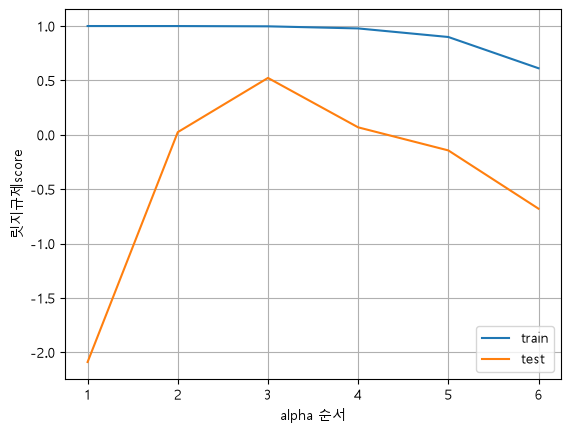

In [67]:
# 어느 알파값이 가장 정확? 차이가 없는가
# 6. alpha별 성능 그래프
# 선그래프
no_list = [1,2,3,4,5,6]
plt.plot(no_list,train_score)
plt.plot(no_list,test_score)

plt.grid()

plt.legend(['train','test'])


plt.xlabel('alpha 순서')
plt.ylabel('릿지규제score')
plt.show()

In [68]:
# 릿지 규제화
ridge = Ridge(alpha=0.1)
ridge.fit(train_scaled,train_label)
# 정확도
score = ridge.score(train_scaled,train_label)
score2 = ridge.score(test_scaled,test_label)

print('train 정확도 : ',score)
print('test 정확도 : ',score2)

train 정확도 :  0.9972983778411562
test 정확도 :  0.5227992065048618
